# Fase 6 — Optimización de modelos y análisis de umbrales

Se revisaron el protocolo v2 de fase 4.2, la comparación de fase 5, sus módulos y los proyectos anteriores del curso. Se conserva la estructura data/notebooks/src/reports y la explicación en español. Este ejercicio es académico y exploratorio, sin garantía de disponibilidad inicial de los predictores. Prueba queda reservada.

## 1. Diseño fijado antes de evaluar

Se mantienen las 54.164 reservas de entrenamiento y 18.097 de validación externa. Tres ventanas internas expansivas: octubre-diciembre 2015, enero-marzo 2016 y abril-junio 2016. En cada ajuste se exige alta y disponibilidad proxy anteriores al inicio; en su validación, alta dentro de la ventana y disponibilidad anterior al fin. Solo intervienen IDs del entrenamiento externo. Los folds no son aleatorios; los subentrenamientos se reutilizan de forma expansiva.

La extracción empieza por llegadas en julio de 2015: las primeras ventanas carecen de un año completo de llegadas realizadas. Que estén representados doce meses previstos mediante cancelaciones futuras no acredita un ciclo observado completo. Se utiliza una búsqueda pequeña, se incluye la configuración inicial y no se afirma estabilidad entre años.

In [1]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Preparar rutas y localizar los checkpoints del experimento de optimización v2.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
from pathlib import Path
import sys, json
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / "src").is_dir(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.optimization import run_optimization


## 2. Búsqueda interna limitada

RandomizedSearchCV, ocho combinaciones muestreadas sin reemplazo más la inicial para cada algoritmo; tres folds, 54 ajustes internos en total. Semilla 42; AP media por periodo como criterio principal, ROC-AUC para desempatar; n_jobs=1 en búsqueda y cuatro hilos por modelo. No se usa early stopping. Se guarda la selección antes de predecir validación externa.

Cada fold clona el pipeline de fase 5 y ajusta sus medianas y categorías únicamente con el subentrenamiento. No se escalan árboles. Las auditorías del scorer comprueban las estadísticas aprendidas contra esas filas concretas. LightGBM activa subsample_freq=1 en nuevas propuestas para que subsample tenga efecto; la referencia conserva freq=0.

In [2]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Mostrar folds y selección interna; si existe checkpoint se reproduce sin buscar otra vez.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
metrics, folds, search_results, calibration, thresholds, verification = run_optimization(ROOT)
display(folds)
display(search_results[search_results.inicial_fase_5 | search_results.seleccionado])
print(json.dumps(verification["parametros_completos_seleccionados"], indent=2, default=str))

Reproducción desde resultados congelados: sin nuevos ajustes o predicciones externas.


,fold,inicio_validacion,fin_exclusivo,n_train,n_validacion,tasa_train,tasa_validacion,apartadas_train_por_disponibilidad,apartadas_val_por_disponibilidad,max_disponibilidad_train,max_disponibilidad_val,sha_ids_train,sha_ids_val
0,0,2015-10-01,2016-01-01,13035,5799,0.510779,0.385066,7487,5919,2015-09-30,2015-12-31,9737972554711f39e790e9fd1de4a0dcac53287395aeed...,472e05870431d322ac0c6e3d0f2f86267e3d71c097a7f6...
1,1,2016-01-01,2016-04-01,25042,9795,0.464659,0.426953,7198,5852,2015-12-31,2016-03-31,9d06e3e591175302110c9a8cfa9dc495679e1fa536bfcd...,f8cd9844796ef5ae090bfec106d2ba44a4cd30b4c421b9...
2,2,2016-04-01,2016-07-01,39334,6277,0.466899,0.414529,8553,0,2016-03-31,2016-06-30,fa34efb90f2eab167040a94496405613f01d99a685a8f3...,91931082b4c24140f060fc6bcac521874fc7c0b259df50...


,modelo,candidato,seleccionado,inicial_fase_5,parametros,mean_ap,std_ap,mean_roc_auc,std_roc_auc,mean_fit_seconds,fold_0_ap,fold_0_roc_auc,fold_1_ap,fold_1_roc_auc,fold_2_ap,fold_2_roc_auc
0,xgboost,0,False,True,"{""classifier__colsample_bytree"": 0.8, ""classif...",0.535215,0.063027,0.571454,0.099329,0.244860,0.543154,0.701349,0.608131,0.552817,0.454361,0.460194
6,xgboost,6,True,False,"{""classifier__colsample_bytree"": 0.8, ""classif...",0.600819,0.105548,0.656801,0.135738,0.159318,0.682017,0.815434,0.668691,0.671101,0.451751,0.483869
9,lightgbm,0,False,True,"{""classifier__colsample_bytree"": 1.0, ""classif...",0.509424,0.104560,0.560118,0.147949,0.220525,0.555529,0.741037,0.608046,0.560679,0.364696,0.378639
15,lightgbm,6,True,False,"{""classifier__colsample_bytree"": 0.8, ""classif...",0.600621,0.092800,0.640552,0.139454,0.232768,0.680278,0.809295,0.651117,0.644584,0.470467,0.467776


{
  "xgboost": {
    "objective": "binary:logistic",
    "base_score": null,
    "booster": null,
    "callbacks": null,
    "colsample_bylevel": null,
    "colsample_bynode": null,
    "colsample_bytree": 0.8,
    "device": null,
    "early_stopping_rounds": null,
    "enable_categorical": true,
    "eval_metric": "logloss",
    "feature_types": null,
    "feature_weights": null,
    "gamma": null,
    "grow_policy": null,
    "importance_type": null,
    "interaction_constraints": null,
    "learning_rate": 0.08,
    "max_bin": null,
    "max_cat_threshold": null,
    "max_cat_to_onehot": null,
    "max_delta_step": null,
    "max_depth": 5,
    "max_leaves": null,
    "min_child_weight": 10,
    "missing": "NaN",
    "monotone_constraints": null,
    "multi_strategy": null,
    "n_estimators": 200,
    "n_jobs": 4,
    "num_parallel_tree": null,
    "random_state": 42,
    "reg_alpha": null,
    "reg_lambda": 1.0,
    "sampling_method": null,
    "scale_pos_weight": null,
    "subsa

## 3. Evaluación externa

Las dos configuraciones seleccionadas se ajustan al entrenamiento externo completo y se predicen una vez. Las referencias logística, XGBoost y LightGBM iniciales se recuperan de las probabilidades congeladas de fase 5 y sus métricas se verifican. Umbral 0,5 para la primera comparación. No se vuelve a buscar al observar validación.

In [3]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Comparar métricas externas y calibración descriptiva de las configuraciones históricas.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(metrics.round(6))
display(calibration.round(6))
print("Brier constante basado en tasa de train:", verification["brier_constante_tasa_train"])

,modelo,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,fit_seconds,predict_seconds,origen
0,regresion_logistica,0.747085,0.807633,0.537727,0.645606,0.820718,0.807536,9351,993,3584,4169,0.267440,0.018964,fase_5_guardado
1,xgboost,0.765707,0.862988,0.538630,0.663278,0.858927,0.842275,9681,663,3577,4176,0.459084,0.038361,fase_5_guardado
2,lightgbm,0.745925,0.863731,0.483168,0.619686,0.848655,0.830643,9753,591,4007,3746,0.381800,0.067237,fase_5_guardado
3,xgboost_optimizado,0.756811,0.859966,0.516445,0.645338,0.855129,0.838477,9692,652,3749,4004,0.298991,0.032654,fase_6_seleccion_interna
4,lightgbm_optimizado,0.744156,0.856588,0.483813,0.618365,0.843851,0.827120,9716,628,4002,3751,0.421834,0.065847,fase_6_seleccion_interna


,modelo,brier,probabilidad_media,tasa_observada,brecha_media,ece_10_bins_descriptivo
0,regresion_logistica,0.172022,0.355470,0.428414,-0.072944,0.072944
1,xgboost,0.155458,0.356801,0.428414,-0.071612,0.071612
2,lightgbm,0.171287,0.317930,0.428414,-0.110483,0.110483
3,xgboost_optimizado,0.159277,0.346269,0.428414,-0.082144,0.082144
4,lightgbm_optimizado,0.171001,0.322605,0.428414,-0.105809,0.105809


Brier constante basado en tasa de train: 0.24488119316862128


## 4. Umbrales, calibración y negocio

Se exploran umbrales prefijados de 0,1 a 0,9 solo con validación. Ordenación (ROC-AUC/AP), calidad probabilística (Brier/curvas) y decisión de contacto son cuestiones distintas. Los bins de calibración tienen amplitud 0,1, con tamaños exportados; no se ajusta ningún calibrador sobre validación.

FP: seguimiento innecesario y posibles molestias. FN: cancelación no anticipada. Se ilustran pesos relativos (FP,FN)=(1,1),(1,5),(5,1), unidades arbitrarias, no euros ni costes reales. La carga de errores no estima rentabilidad ni el efecto de un contacto. No se decide umbral definitivo; la capacidad de atención y la eficacia de intervención deben medirse. Contacto preventivo o solicitud de confirmación requieren revisión humana, sin cancelaciones automáticas ni penalizaciones basadas en el score.

,modelo,umbral,precision,recall,f1,fp,fn,tp,tn,alertas,porcentaje_alto_riesgo
0,regresion_logistica,0.1,0.5166,0.9409,0.6670,6825,458,7295,3519,14120,78.0240
1,regresion_logistica,0.2,0.6075,0.8332,0.7027,4174,1293,6460,6170,10634,58.7611
2,regresion_logistica,0.3,0.6820,0.7321,0.7062,2646,2077,5676,7698,8322,45.9855
3,regresion_logistica,0.4,0.7513,0.6323,0.6867,1623,2851,4902,8721,6525,36.0557
4,regresion_logistica,0.5,0.8076,0.5377,0.6456,993,3584,4169,9351,5162,28.5241
5,regresion_logistica,0.6,0.8584,0.4605,0.5994,589,4183,3570,9755,4159,22.9817
6,regresion_logistica,0.7,0.9111,0.3849,0.5412,291,4769,2984,10053,3275,18.0969
7,regresion_logistica,0.8,0.9697,0.2803,0.4349,68,5580,2173,10276,2241,12.3833
8,regresion_logistica,0.9,0.9953,0.1652,0.2834,6,6472,1281,10338,1287,7.1117
9,xgboost,0.1,0.5486,0.9659,0.6998,6161,264,7489,4183,13650,75.4269


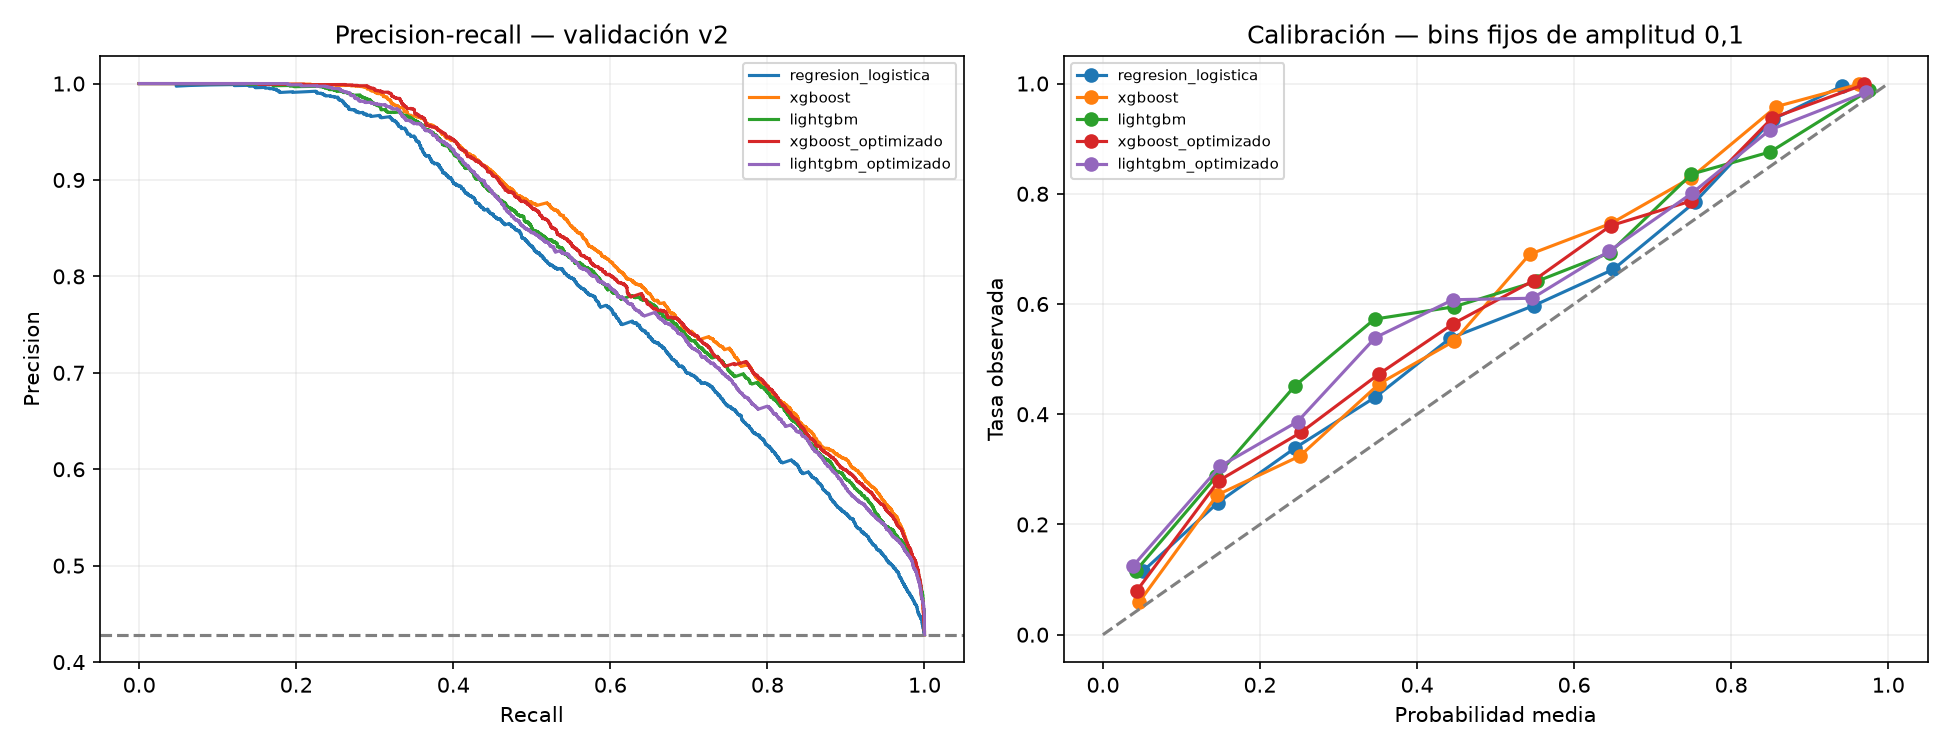

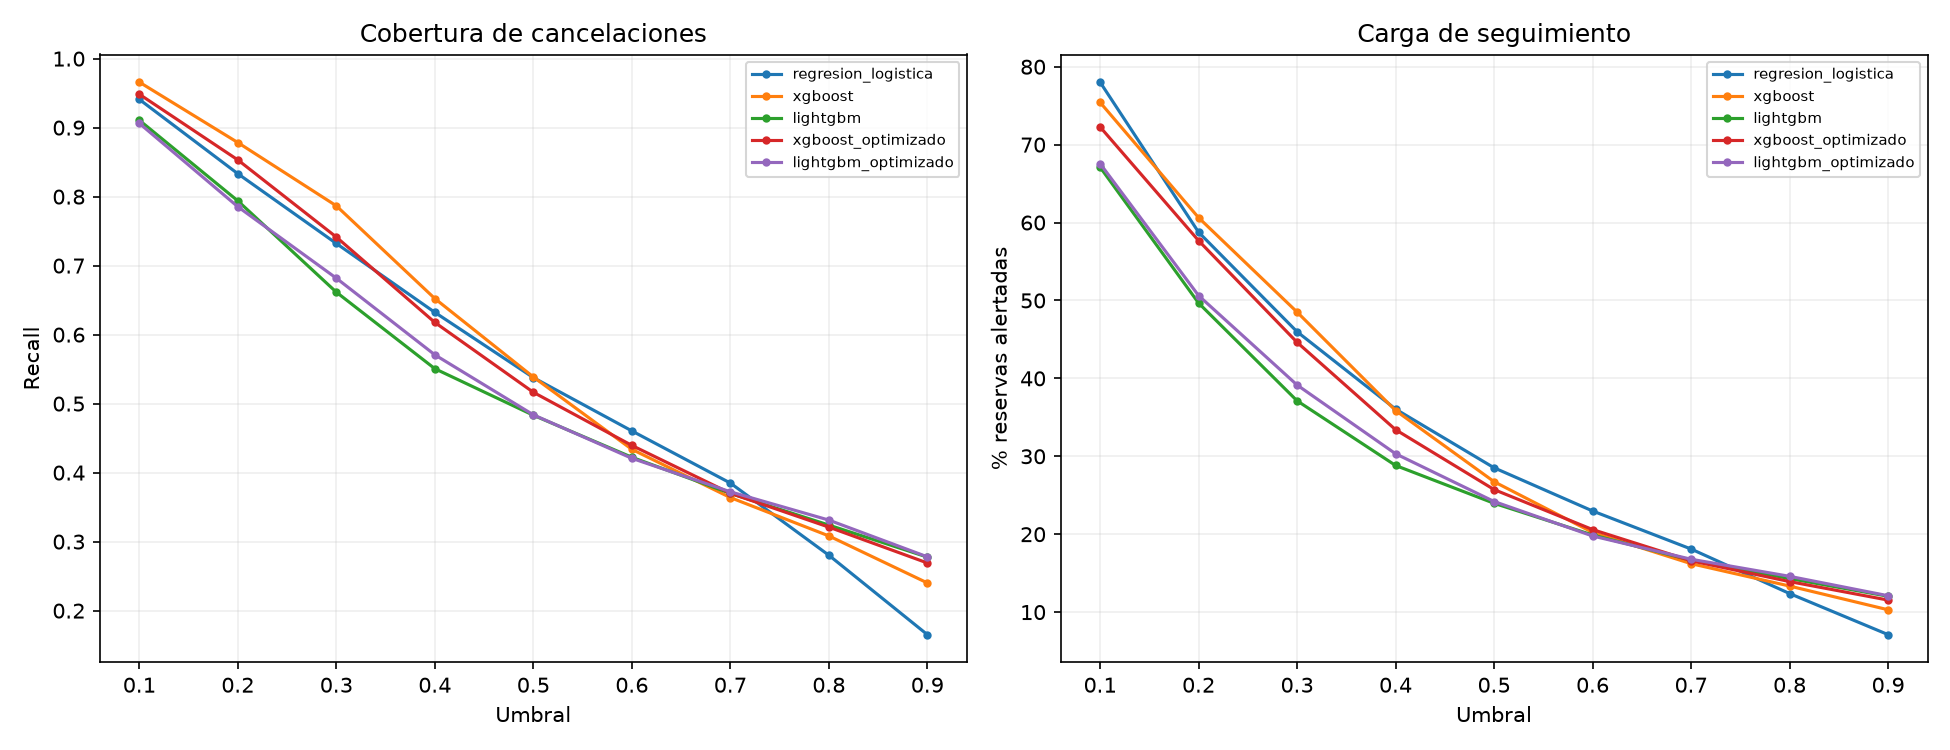

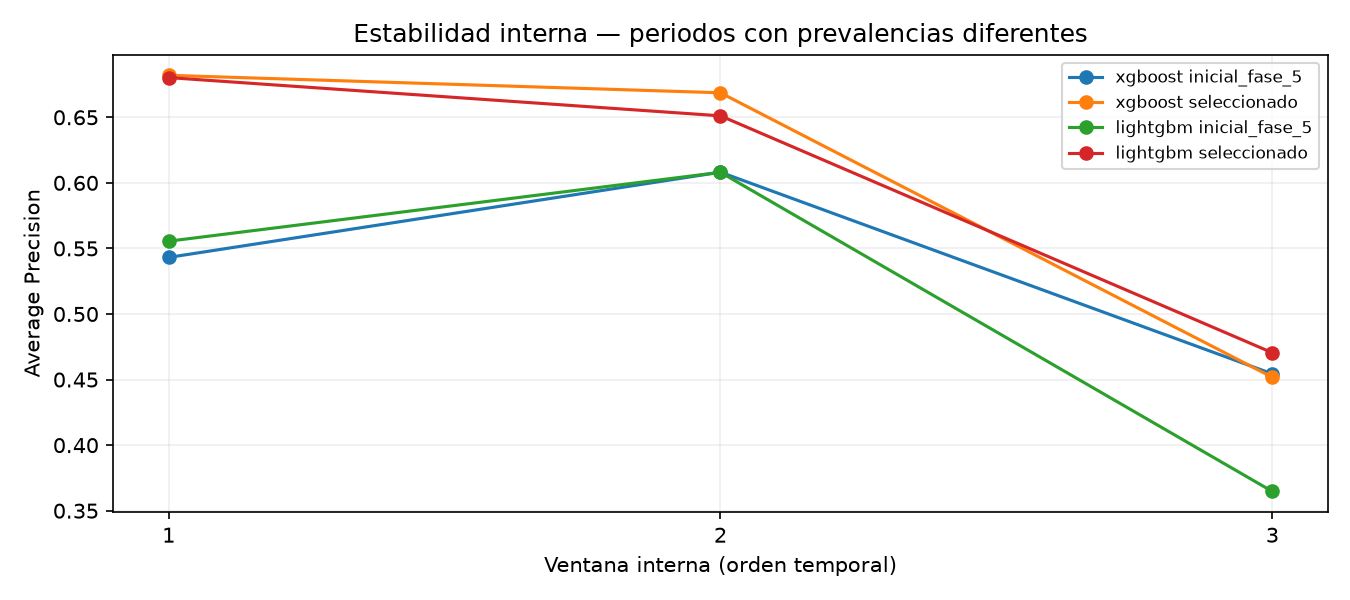

In [4]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Examinar umbrales e inestabilidad sin fijar una decisión con datos de prueba.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
display(thresholds.round(4))
for name in ["pr_calibracion", "umbrales", "estabilidad"]:
    display(Image(filename=str(ROOT / f"reports/figures/optimizacion_6_{name}.png")))

## 5. Verificaciones y límites

Se conservan SHA-256 del original, preparado, manifiesto, reportes previos y módulos del protocolo. Las predicciones exportadas contienen únicamente IDs de validación externa. Se registran parámetros completos, versiones, tiempos, todos los ensayos y asignaciones internas. La reproducción se apoya en semillas, muestreo fijo, hashes y pruebas sintéticas; no se repite la evaluación externa para escoger alternativas.

La disponibilidad de etiquetas es aproximada y condiciona las cohortes; no hay snapshots iniciales ni cierre PMS acreditado. Duplicados, selección temporal, validación externa ya explorada en fase 5 y variación de prevalencia limitan inferencias. Una calibración futura necesitaría un bloque temporal separado dentro de entrenamiento, con etiquetas disponibles y modelo base entrenado antes, más evaluación posterior no utilizada para calibrar; la escasa historia y el tuning previo deben considerarse. No se implementa aquí. No se inicia SHAP ni se evalúa prueba.

## Conclusiones de la ejecución

Se seleccionaron XGBoost (200 árboles, profundidad 5, tasa 0,08, min_child_weight=10) y LightGBM (400 árboles, 15 hojas, tasa 0,08, mínimo 60 por hoja) mediante CV interna. Ambos empeoran ROC-AUC y AP externos frente a sus versiones iniciales. Se conserva **XGBoost inicial de fase 5** como candidato provisional: ROC-AUC 0,8589; AP 0,8423; Brier 0,15546. Su promedio predicho 35,68% infravalora el 42,84% observado.

Los folds internos son inestables: el tercero tiene ROC-AUC 0,4839 para XGBoost seleccionado y 0,4678 para LightGBM seleccionado. No se concluye generalización sólida por la media. A umbral 0,3, XGBoost inicial detecta 78,67% de cancelaciones pero alerta 48,51% de reservas, frente a 53,86% y 26,74% a 0,5. No se fija un umbral operativo.

La primera ejecución realizó la búsqueda y las dos predicciones externas; falló al exportar el registro final por un default NaN. Se recuperaron los resultados sin repetir predicciones. Esta ejecución completa presenta y verifica esa evidencia congelada. Se propone revisar explicabilidad y errores tras autorización, además de obtener snapshots y diseñar calibración temporal independiente. No se ha iniciado esa fase.

In [5]:
# EDICIÓN COMENTADA PARA LECTURA. Las fuentes ejecutadas y selladas permanecen en la raíz.
# Verificar el experimento y las huellas de los datos e informes anteriores.
# Solo se añaden comentarios: no se han ejecutado instrucciones de esta copia.
import io, unittest
from src.comparison import sha
# Seleccionar las pruebas de esta llamada; los conjuntos históricos pueden incluir entrenamientos.
suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
log = io.StringIO()
# Ejecutar la batería indicada y conservar su salida; comprobar qué pruebas admite esta fase.
result = unittest.TextTestRunner(stream=log, verbosity=1).run(suite)
print(log.getvalue())
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert result.wasSuccessful()
for name, expected in verification["archivos_previos_intactos"].items():
    # La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
    assert sha(ROOT / name) == expected, name
print("Pruebas superadas:", result.testsRun)
# Hacer explícito este invariante: si falla, no se deben interpretar los resultados como válidos.
assert verification["prueba_transformada_predicha_evaluada"] is False
print("Fin exclusivo de fase 6. Informe: reports/fase_6_optimizacion.md")

..........................
----------------------------------------------------------------------
Ran 26 tests in 0.591s

OK

Pruebas superadas: 26
Fin exclusivo de fase 6. Informe: reports/fase_6_optimizacion.md
